# Swift–Hohenberg

$$
f_t = r\,f - (1 + \Delta)^2 f - f^3 = (r-1)\,f - 2\,\Delta f - \Delta^2 f - f^3, \qquad r = 0.3
$$

## 1. Setup

In [1]:
import numpy as np

import nb_helpers as nb
from equivariant_pde_find.simulations import swift_hohenberg

EQ = "sh"
NOISE = 0.02

# ── Best configurations from the hyperparameter sweep ───────────────
#
#   "eq"  = best of  multigraph / mod_multigraph
#   "neq" = best of  pdefind / wsindy / polyjet
#
# ────────────────────────────────────────────────────────────────────
BEST = {
    (0.00, "eq"): dict(
        library="multigraph", method="space_weak_ibp", algorithm="stridge",
        backend="spectral", m=12, lam=1e-6, d_tol=1.0,
    ),
    (0.00, "neq"): dict(
        library="pdefind", method="space_weak_ibp", algorithm="stridge",
        backend="spectral", m=12, lam=1e-6, d_tol=1.0,
    ),
    (0.02, "eq"): dict(
        library="multigraph", method="space_weak_ibp", algorithm="stridge",
        backend="spectral", m=12, lam=1e-6, d_tol=1.0,
    ),
    (0.02, "neq"): dict(
        library="pdefind", method="space_weak_ibp", algorithm="stridge",
        backend="spectral", m=12, lam=1e-6, d_tol=1.0,
    ),
}

## 2. Generate the data

In [2]:
SIM = dict(N=64, L=8 * np.pi, T_end=50.0, r=0.3, dt=0.1,
           save_every=5, seed=42)

clean, times = swift_hohenberg(**SIM, obs_noise=0.0)
noisy, _ = swift_hohenberg(**SIM, obs_noise=NOISE)

print(f'{len(clean)} snapshots over t ∈ [{times[0]:.2f}, {times[-1]:.2f}]'
      f' on a {clean.shape[1]}×{clean.shape[2]} grid')
print(f'f ∈ [{clean.min():.3f}, {clean.max():.3f}]')
nb.check_matches_dataset(clean, EQ, 'clean')
nb.check_matches_dataset(noisy, EQ, 'noise2pct')

101 snapshots over t ∈ [0.10, 50.10] on a 64×64 grid
f ∈ [-0.756, 0.719]
  vs data/sh_clean.npz: max|Δ| = 0.00e+00  → identical
  vs data/sh_noise2pct.npz: max|Δ| = 1.11e-16  → identical


1.1102230246251565e-16

## 3. The motion

written: results/figures/sh_motion.pdf
written: results/figures/sh_motion.png


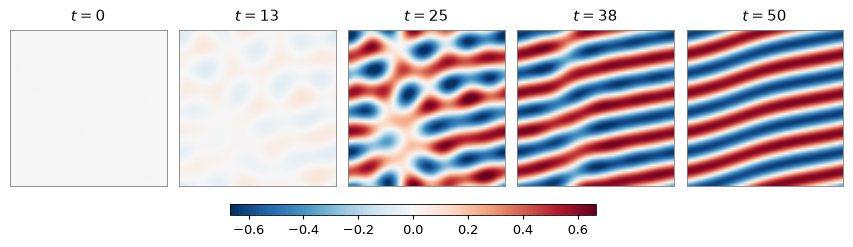

In [3]:
fig, paths = nb.plot_motion(
    clean, times, SIM['L'], n_frames=5,
    cmap='RdBu_r', symmetric=True,
    time_fmt='.0f',
    save_as=f'{EQ}_motion',
)
for p in paths:
    print('written:', p.split('/code/')[-1])

## 4. Design matrices

In [4]:
Lx = Ly = SIM['L']

data = {
    0.00: nb.regression_data(clean, times, EQ),
    NOISE: nb.regression_data(noisy, times, EQ),
}
print(f'{len(data[0.00][0])} interior snapshots')

ev = nb.JetEvaluator(clean, times, Lx, Ly, EQ)
ev.summary()

designs, fits = {}, {}
for key, cfg in BEST.items():
    f_snaps, ft_snaps, idx_sets, _ = data[key[0]]
    Theta, Ft, desc = nb.build_design(
        f_snaps, ft_snaps, idx_sets, Lx, Ly, cfg)
    designs[key] = (Theta, Ft, desc)
    fits[key] = nb.run_fit(Theta, Ft, cfg)
    print(f'{key[0] * 100:>3.0f}%  {key[1]:<4} {cfg["library"]:<15} '
          f'Theta {str(Theta.shape):<13} cond {np.linalg.cond(Theta):.2e}')

89 interior snapshots


Evaluation space: 119 jet monomials, 364,544 rows, 7 true active terms


  0%  eq   multigraph      Theta (8900, 20)    cond 2.87e+04


  0%  neq  pdefind         Theta (8900, 60)    cond 3.53e+04


  2%  eq   multigraph      Theta (8900, 20)    cond 3.35e+03


  2%  neq  pdefind         Theta (8900, 60)    cond 6.74e+03


## 5. Recovery with clean data

In [5]:
print('Ground truth:  f_t = −0.7·f − f³ − 2·Δf − Δ²f')
print()
for group in ('eq', 'neq'):
    key = (0.00, group)
    nb.show_recovery(fits[key], designs[key][2], BEST[key], ev)
    print()

Ground truth:  f_t = −0.7·f − f³ − 2·Δf − Δ²f

── Multigraph ──
   Multigraph · weak (IBP) · STRidge · spectral derivatives · m=12, p=6 · λ=1e-06, d_tol=1
   f_t = (-0.71088)f + (-1.02306)f³ + (-2.03784)Δf + (-1.02016)Δ²f
   4 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.02239   max|Δc| = 0.0403

── PDE-FIND ──
   PDE-FIND · weak (IBP) · STRidge · spectral derivatives · m=12, p=6 · λ=1e-06, d_tol=1
   f_t = (-2.04777)f_yy + (-2.04642)f_xx + (-1.02618)f_yyyy + (-2.04368)f_xxyy + (-1.02536)f_xxxx + (-0.71464)f + (-1.02354)f³
   7 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.02305   max|Δc| = 0.0478



In [6]:
for group in ('eq', 'neq'):
    key = (0.00, group)
    print(nb.LIBRARY_LABEL[BEST[key]['library']] + ':')
    nb.coefficient_table(
        fits[key], designs[key][2], BEST[key], ev)
    print()

Multigraph:
term       recovered        true       error
────────────────────────────────────────────
f_xx        -2.03784    -2.00000   -3.78e-02
f_yy        -2.03784    -2.00000   -3.78e-02
f_xxyy      -2.04033    -2.00000   -4.03e-02
f³          -1.02306    -1.00000   -2.31e-02
f_xxxx      -1.02016    -1.00000   -2.02e-02
f_yyyy      -1.02016    -1.00000   -2.02e-02
f           -0.71088    -0.70000   -1.09e-02

PDE-FIND:
term       recovered        true       error
────────────────────────────────────────────
f_xx        -2.04642    -2.00000   -4.64e-02
f_yy        -2.04777    -2.00000   -4.78e-02
f_xxyy      -2.04368    -2.00000   -4.37e-02
f³          -1.02354    -1.00000   -2.35e-02
f_xxxx      -1.02536    -1.00000   -2.54e-02
f_yyyy      -1.02618    -1.00000   -2.62e-02
f           -0.71464    -0.70000   -1.46e-02



## 6. Recovery at 2 % noise

In [7]:
print('Ground truth:  f_t = −0.7·f − f³ − 2·Δf − Δ²f')
print()
for group in ('eq', 'neq'):
    key = (NOISE, group)
    nb.show_recovery(fits[key], designs[key][2], BEST[key], ev)
    print()

Ground truth:  f_t = −0.7·f − f³ − 2·Δf − Δ²f

── Multigraph ──
   Multigraph · weak (IBP) · STRidge · spectral derivatives · m=12, p=6 · λ=1e-06, d_tol=1
   f_t = (-0.70074)f + (-1.01895)f³ + (-2.01422)Δf + (-1.00788)Δ²f
   4 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.0278   max|Δc| = 0.0189



── PDE-FIND ──
   PDE-FIND · weak (IBP) · STRidge · spectral derivatives · m=12, p=6 · λ=1e-06, d_tol=1
   f_t = (-2.02133)f_yy + (-2.02180)f_xx + (-1.01198)f_yyyy + (-2.01772)f_xxyy + (-1.01271)f_xxxx + (-0.70378)f + (-1.01935)f³
   7 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.02367   max|Δc| = 0.0218



In [8]:
for group in ('eq', 'neq'):
    key = (NOISE, group)
    print(nb.LIBRARY_LABEL[BEST[key]['library']] + ':')
    nb.coefficient_table(
        fits[key], designs[key][2], BEST[key], ev)
    print()

Multigraph:
term       recovered        true       error
────────────────────────────────────────────
f_xx        -2.01422    -2.00000   -1.42e-02
f_yy        -2.01422    -2.00000   -1.42e-02
f_xxyy      -2.01576    -2.00000   -1.58e-02
f³          -1.01895    -1.00000   -1.89e-02
f_xxxx      -1.00788    -1.00000   -7.88e-03
f_yyyy      -1.00788    -1.00000   -7.88e-03
f           -0.70074    -0.70000   -7.38e-04

PDE-FIND:
term       recovered        true       error
────────────────────────────────────────────
f_xx        -2.02180    -2.00000   -2.18e-02
f_yy        -2.02133    -2.00000   -2.13e-02
f_xxyy      -2.01772    -2.00000   -1.77e-02
f³          -1.01935    -1.00000   -1.94e-02
f_xxxx      -1.01271    -1.00000   -1.27e-02
f_yyyy      -1.01198    -1.00000   -1.20e-02
f           -0.70378    -0.70000   -3.78e-03

